# Stage 4: Analyze. What made my videos work?

**66 public videos, Aug 2011 – Dec 2019** (the clean analysis set from [Stage 3](../3_Clean/README.md)).

Each question below has: the code → the numbers → a quick chart → **the answer in plain English**.
Polished presentation charts come in Stage 5. At the end, I check the predictions I wrote down in
[Stage 1](../1_Idea/project_brief.md) *before* seeing any data.

> **A note on medians:** a few viral videos have 10–30× the views of a typical one. An *average* gets
> dragged up by those few, so most comparisons here use the **median** (the middle video), which shows
> what a *typical* video did.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

pd.set_option("display.width", 140)
ROOT = Path.cwd().parent if Path.cwd().name == "4_Analyze" else Path.cwd()
df = pd.read_csv(ROOT / "3_Clean" / "videos_clean.csv")
a = df[df["in_analysis"] == 1].copy()

BLUE, ORANGE, GRAY, TEXT, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#b9b8b2", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "figure.dpi": 110,
})
LENGTH_ORDER = ["<30s", "30s–1m", "1–2m", "2–5m", "5m+"]
print(f"{len(a)} videos · {a['views'].sum():,.0f} lifetime views · {a['subs_gained'].sum():,.0f} subscribers gained")

66 videos · 528,093 lifetime views · 1,843 subscribers gained


## Q1. Growth: how did my output and results change year by year?

In [2]:
by_year = a.groupby("publish_year").agg(videos=("video", "size"), total_views=("views", "sum"),
                                        median_views=("views", "median"), subs_gained=("subs_gained", "sum"))
by_year["pct_of_views"] = (by_year["total_views"] / by_year["total_views"].sum() * 100).round(1)
by_year.index = by_year.index.astype(int)
by_year

,videos,total_views,median_views,subs_gained,pct_of_views
publish_year,,,,,
2011,10,36595.0,3251.5,87.0,6.9
2012,25,196978.0,3051.0,814.0,37.3
2013,16,176598.0,6479.5,591.0,33.4
2014,6,26967.0,3799.0,57.0,5.1
2015,4,14995.0,3776.5,27.0,2.8
2016,3,64204.0,3753.0,155.0,12.2
2019,2,11756.0,5878.0,112.0,2.2


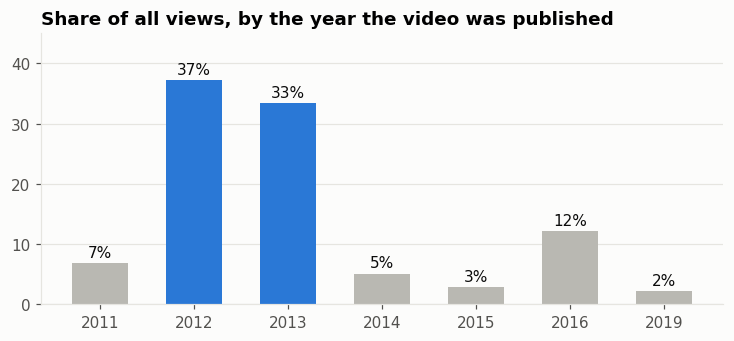

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(by_year.index.astype(str), by_year["pct_of_views"], color=[BLUE if y in (2012, 2013) else GRAY for y in by_year.index], width=0.6)
for i, v in enumerate(by_year["pct_of_views"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", color=TEXT)
ax.set_title("Share of all views, by the year the video was published")
ax.set_ylim(0, 45); ax.grid(axis="x", visible=False)
plt.show()

**Answer:** my channel peaked in **2012–2013**. Videos from those two years bring in **~71% of all views**.
That's when I posted most (41 of 66 videos) *and* when the typical video did best (**2013 median: ~6,500
views**, the highest of any year). After 2013, output dropped sharply and so did total views. The one exception
is a single 2016 video that went viral on its own.

## Q2. Length: did longer videos keep people watching, or lose them?

In [4]:
by_len = (a.groupby("length_bucket")
           .agg(videos=("video", "size"), median_pct_viewed=("avg_pct_viewed", "median"),
                median_seconds_watched=("avg_view_sec", "median"), median_views=("views", "median"),
                median_watch_hours=("watch_hours", "median"), share_looped=("is_looped", "mean"))
           .reindex(LENGTH_ORDER).round(1))
by_len["share_looped"] = (by_len["share_looped"] * 100).round(0).astype(int).astype(str) + "%"
by_len

,videos,median_pct_viewed,median_seconds_watched,median_views,median_watch_hours,share_looped
length_bucket,,,,,,
<30s,12,108.9,11.5,2928.0,10.0,80%
30s–1m,16,94.4,37.0,8445.0,95.1,40%
1–2m,15,73.9,59.0,3833.0,47.2,10%
2–5m,8,56.9,85.5,4367.5,95.2,0%
5m+,15,23.0,121.0,1698.0,22.9,0%


Length vs % viewed: Spearman correlation = -0.90 (p = 3.3e-25)


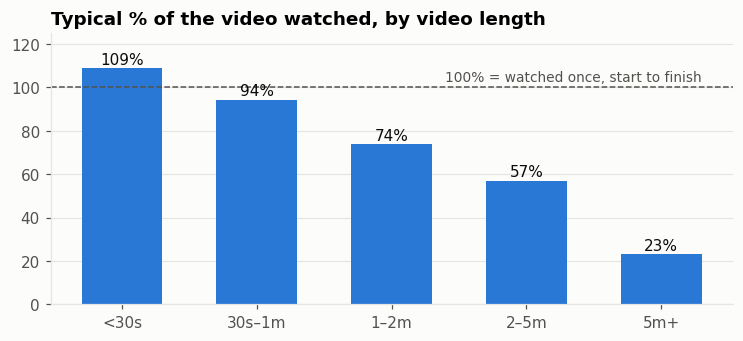

In [5]:
rho, p = stats.spearmanr(a["duration_sec"], a["avg_pct_viewed"])
print(f"Length vs % viewed: Spearman correlation = {rho:.2f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(LENGTH_ORDER, by_len["median_pct_viewed"], color=BLUE, width=0.6)
ax.axhline(100, color=MUTED, linestyle="--", linewidth=1)
ax.text(4.3, 103, "100% = watched once, start to finish", ha="right", color=MUTED, fontsize=9)
for i, v in enumerate(by_len["median_pct_viewed"]):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", color=TEXT)
ax.set_title("Typical % of the video watched, by video length")
ax.set_ylim(0, 125); ax.grid(axis="x", visible=False)
plt.show()

**Answer: yes, longer videos lost people, and it's the strongest pattern in the whole dataset.**

- **Under 30 seconds:** the typical viewer watched **109%**, meaning they replayed it. 8 in 10 of these got looped.
- **Over 5 minutes:** the typical viewer watched only **23%**.
- The correlation between length and % watched is **−0.90**. A perfect relationship would be −1.0, so this is very strong.

What surprised me is that **short didn't mean less total watch time.** The **30-second to 1-minute** videos had the
highest median views (~8,400) *and* tied for the most watch hours per video. Long videos were worse on both counts.
**The sweet spot was 30 seconds to 2 minutes.**

*(Statistics note: "correlation" means the two move together. It doesn't prove length* caused *the drop.)*

## Q3. Timing: did the day I posted make a difference?

In [6]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = a.groupby("publish_weekday").agg(videos=("video", "size"), median_views=("views", "median"),
                                          average_views=("views", "mean")).reindex(DAYS).round(0)
print(by_day)

h, p = stats.kruskal(*[g["views"] for _, g in a.groupby("publish_weekday")])
print(f"\nKruskal-Wallis test across weekdays: p = {p:.3f}")

                 videos  median_views  average_views
publish_weekday                                     
Monday                9        1525.0         1396.0
Tuesday               6        7984.0         7974.0
Wednesday            10        5215.0         5609.0
Thursday             14        3472.0        13942.0
Friday                6        3246.0         8358.0
Saturday             12        3620.0         5159.0
Sunday                9        4431.0        11594.0

Kruskal-Wallis test across weekdays: p = 0.055


**Answer: no reliable difference.** The medians range from ~1,500 (Monday) to ~8,000 (Tuesday), which *looks*
big. But each day only has **6–14 videos**, and one viral video can flip a whole day's average (look how different
the average and median columns are).

To check, I ran a **Kruskal-Wallis test**, which asks: *"Are these differences bigger than what random chance
would produce?"* The result (p = 0.055) doesn't clear the usual bar of 0.05. **The data can't tell posting days
apart, so the content mattered far more than the day.**

## Q4. Engagement: which videos turned viewers into subscribers?

In [7]:
ranked = a.sort_values("views", ascending=False)
top_n = round(len(a) * 0.10)
top = ranked.head(top_n)
print(f"Top {top_n} videos (10% of the catalogue):")
print(f"  {top['views'].sum() / a['views'].sum():.0%} of all views")
print(f"  {top['subs_gained'].sum() / a['subs_gained'].sum():.0%} of all subscribers gained")
print()
print("What they have in common:")
print("  Category:", top["category"].value_counts().to_dict())
print("  Length:  ", top["length_bucket"].value_counts().to_dict())
print("  Year:    ", top["publish_year"].astype(int).value_counts().to_dict())

Top 7 videos (10% of the catalogue):
  54% of all views
  64% of all subscribers gained

What they have in common:
  Category: {'Music animation': 6, 'Comedy animation': 1}
  Length:   {'30s–1m': 4, '1–2m': 2, '<30s': 1}
  Year:     {2013: 4, 2012: 2, 2016: 1}


In [8]:
rates = (a.groupby("category")[["subs_gained_per_1k_views", "likes_per_1k_views", "comments_per_1k_views"]]
           .median().round(2).sort_values("subs_gained_per_1k_views", ascending=False))
rates

,subs_gained_per_1k_views,likes_per_1k_views,comments_per_1k_views
category,,,
Music animation,2.49,14.82,5.90
Comedy animation,2.30,18.42,5.82
Gameplay & let's play,1.66,13.80,9.06
Comedy shorts & skits,1.52,24.30,14.13


**Answer: a handful of hits did most of the work.** Just **7 videos (10% of the catalogue)** brought in
**54% of all views and 64% of all subscribers**. Six of those seven are **music animations**, all under 2 minutes,
mostly from 2012–2013.

Per 1,000 views, **music animations** (2.5 subs) and **comedy animations** (2.3 subs) converted viewers into
subscribers best. Gameplay (1.7) and live-action skits (1.5) converted noticeably less.
**Animation is what people subscribed for.**

## Q5. Content: which types of video performed best?

In [9]:
by_cat = a.groupby("category").agg(videos=("video", "size"), total_views=("views", "sum"),
                                   median_views=("views", "median"), median_pct_viewed=("avg_pct_viewed", "median"),
                                   subs_gained=("subs_gained", "sum"))
by_cat["pct_of_views"] = (by_cat["total_views"] / by_cat["total_views"].sum() * 100).round(1)
by_cat["pct_of_videos"] = (by_cat["videos"] / by_cat["videos"].sum() * 100).round(1)
by_cat = by_cat.sort_values("total_views", ascending=False)
print(by_cat)

h, p = stats.kruskal(*[g["views"] for _, g in a.groupby("category")])
print(f"\nKruskal-Wallis test across categories: p = {p:.4f}")

                       videos  total_views  median_views  median_pct_viewed  subs_gained  pct_of_views  pct_of_videos
category                                                                                                             
Music animation            19     322964.0        3897.0              88.42       1266.0          61.2           28.8
Comedy animation           24     156549.0        6083.5              86.49        479.0          29.6           36.4
Gameplay & let's play      18      34672.0        1953.5              31.90         75.0           6.6           27.3
Comedy shorts & skits       5      13908.0        1698.0              52.01         23.0           2.6            7.6

Kruskal-Wallis test across categories: p = 0.0005


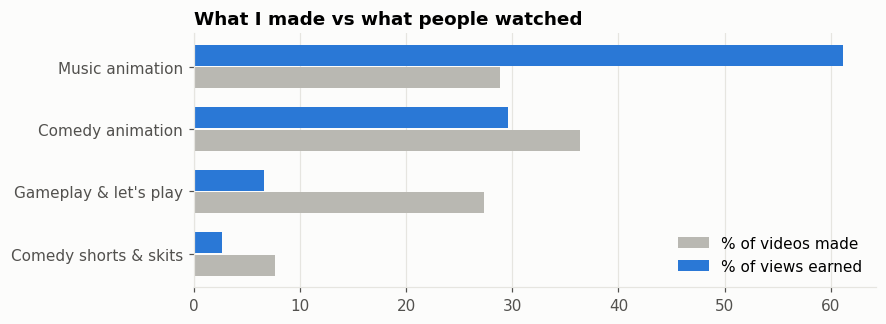

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
y = range(len(by_cat))
ax.barh([i + 0.18 for i in y], by_cat["pct_of_videos"], height=0.34, color=GRAY, label="% of videos made")
ax.barh([i - 0.18 for i in y], by_cat["pct_of_views"], height=0.34, color=BLUE, label="% of views earned")
ax.set_yticks(list(y), by_cat.index); ax.invert_yaxis()
ax.set_title("What I made vs what people watched"); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

**Answer: music animations, by a mile.** They were **29% of the videos I made but earned 61% of all views**
and 69% of subscribers. **Gameplay was the opposite:** 27% of my videos, only 7% of views, and people watched
just ~32% of each one.

There's a nuance worth noting. **Comedy animations had the highest *median* views** (~6,100 vs ~3,900 for music).
So comedy animation was the more *consistent* performer, while music animation was *hit-driven*, with fewer but
much bigger successes.

This one passes the statistics check: the category differences are far bigger than chance (p < 0.001).

## Q6. Long tail: do my videos still get watched years after I stopped?

In [11]:
tail_total = a["views_after_2019"].sum()
print(f"Views earned since Jan 2020: {tail_total:,.0f} ({tail_total / a['views'].sum():.1%} of lifetime views)")
print(f"Videos still getting views since 2020: {(a['views_after_2019'] > 0).sum()} of {len(a)}")
print()
tail = a.groupby("category").apply(lambda g: pd.Series({
    "views_since_2020": g["views_after_2019"].sum(),
    "pct_of_lifetime": round(g["views_after_2019"].sum() / g["views"].sum() * 100, 1)}), include_groups=False)
tail.sort_values("pct_of_lifetime", ascending=False)

Views earned since Jan 2020: 37,754 (7.1% of lifetime views)
Videos still getting views since 2020: 61 of 66



,views_since_2020,pct_of_lifetime
category,,
Comedy animation,17990.0,11.5
Music animation,17562.0,5.4
Comedy shorts & skits,651.0,4.7
Gameplay & let's play,1551.0,4.5


**Answer: yes, a little, and almost all of them.** Since I stopped posting, the videos have earned
**~37,000 more views (7% of their lifetime total)**, and **61 of 66** have picked up new views since 2020.
Comedy animations aged best: **11.5%** of their views came after 2019.
It's a slow trickle, not a second life, but the catalogue never fully stopped working.

## The same six questions in SQL
Every answer above is cross-checked in SQL ([`queries.sql`](queries.sql)), run against the same clean data in SQLite.

In [12]:
con = sqlite3.connect(":memory:")
a.to_sql("videos", con, index=False)
for block in (ROOT / "4_Analyze" / "queries.sql").read_text(encoding="utf-8").split("-- name: ")[1:]:
    name, query = block.split("\n", 1)
    print(f"── {name.strip()} ──")
    print(pd.read_sql(query, con).to_string(index=False))
    print()

── q1_growth_by_year ──
 publish_year  videos  total_views  pct_of_all_views  subs_gained
       2011.0      10      36595.0               6.9         87.0
       2012.0      25     196978.0              37.3        814.0
       2013.0      16     176598.0              33.4        591.0
       2014.0       6      26967.0               5.1         57.0
       2015.0       4      14995.0               2.8         27.0
       2016.0       3      64204.0              12.2        155.0
       2019.0       2      11756.0               2.2        112.0

── q2_length_vs_retention ──
length_bucket  videos  avg_pct_viewed  avg_seconds_watched  total_watch_hours  videos_looped_over_100pct
         <30s      12           108.5                 14.0              495.0                          9
       30s–1m      16            94.1                 38.0             2677.0                          6
         1–2m      15            73.9                 58.0             2249.0                          

## Scorecard: my Stage 1 predictions vs the data

| # | What I predicted (before seeing data) | Verdict | What the data says |
|---|---|---|---|
| 1 | My later videos performed better than my early ones | ❌ **Wrong** | My best era was 2012–2013 (~71% of views); later videos did worse |
| 2 | Shorter videos kept more viewers watching, but longer videos earned more total watch time | ½ **Half right** | Retention: right (−0.90 correlation). Watch time: wrong, since 30s–1m videos matched or beat long ones |
| 3 | Posting day made little difference | ✅ **Right** | No statistically reliable difference between days |
| 4 | A small number of videos brought in most of the views and subscribers | ✅ **Right** | Top 10% of videos = 54% of views, 64% of subscribers |
| 5 | Some old videos are still getting views | ✅ **Right** | 61 of 66 videos got new views after 2019 (7% of lifetime views) |

**3 right, 1 half right, 1 wrong.** The wrong one is the most useful lesson: I assumed I kept improving, but
the data says my early-2010s music animations were my peak.